In [ ]:
import pandas as pd
import numpy as np

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# path = "/content/drive/MyDrive/final_anime_dataset.csv"
# df = pd.read_csv(path)
df = pd.read_csv("final_anime_dataset.csv")

In [ ]:
url = df["url"].iloc[100]

print(url)

https://cdn.myanimelist.net/images/anime/10/75815.jpg


In [ ]:
df = df.drop(columns=["Unnamed: 0"])

In [ ]:
df.isnull().sum()

,0
title,0
genre,0
overview,80928
url,0


In [ ]:
df.loc[
    (df["overview"].isna()) & (df["genre"] != ""),
    "overview"
] = (
    df["title"] +
    ". This movie belongs to the " +
    df["genre"] +
    " genre."
)

df.loc[
    (df["overview"].isna()) & (df["genre"] == ""),
    "overview"
] = (
    df["title"] + "."
)

In [ ]:
df.isnull().sum()

,0
title,0
genre,0
overview,0
url,0


In [ ]:
print("Duplicate Rows :", df.duplicated(
    subset=["title", "overview", "genre", "url"]
).sum())

Duplicate Rows : 1


In [ ]:
!pip install -q sentence-transformers faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 76.0 MB/s eta 0:00:00


In [ ]:
import faiss
from sentence_transformers import SentenceTransformer

In [ ]:
model = SentenceTransformer("BAAI/bge-small-en-v1.5")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
documents = ("Title:" + df['title'].astype(str) +
             "\nGenre:" + df['genre'].astype(str) +
             "\nOverview:" + df["overview"].astype(str)).tolist()

In [ ]:
embeddings = model.encode(documents,batch_size=512,show_progress_bar=True,convert_to_numpy=True,normalize_embeddings=True)

Batches:   0%|          | 0/267 [00:00<?, ?it/s]

In [ ]:
dimension = embeddings.shape[1]

In [ ]:
index = faiss.IndexFlatIP(dimension)

In [ ]:
index.add(embeddings)

In [ ]:
index.ntotal

136391

In [ ]:
np.save("/content/drive/MyDrive/anime_embeddings.npy",embeddings)

In [ ]:
faiss.write_index(index,"/content/drive/MyDrive/anime_index")
model.save("/content/drive/MyDrive/anime_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Jujutsu Kaisen (TV)


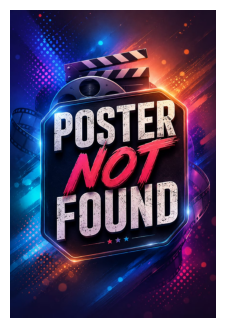

Jujutsu Kaisen


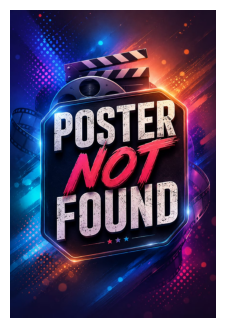

Jujutsu Kaisen


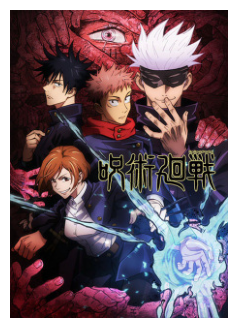

Jujutsu Kaisen 2nd Season


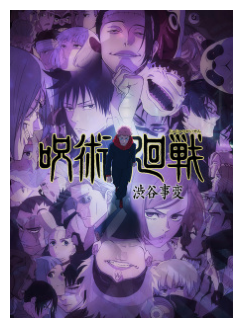

Jujutsu Kaisen: Yoake no Ibara Michi


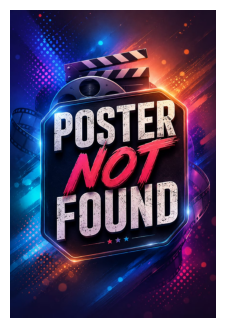

Jujutsu Kaisen: Yuku Natsu to Kaeru Aki


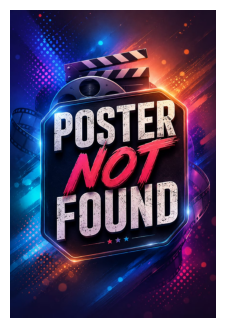

Jujutsu Kaisen 0: Tokyo Toritsu Jujutsu Koutou Senmon Gakkou


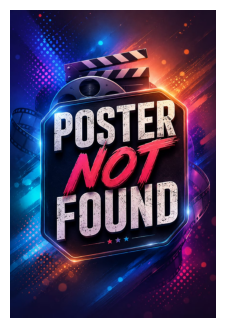

Jujutsu Kaisen


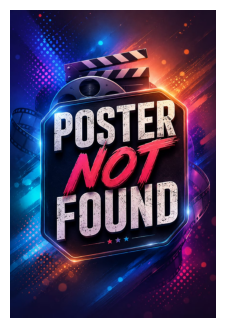

Jujutsu Kaisen


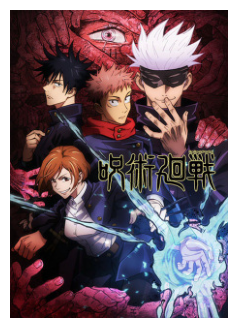

Jujutsu Kaisen Official PV


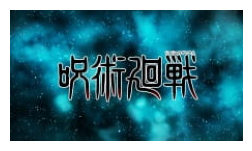

In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt


query = "Jujutsu Kaisen"

query_embedding = model.encode(
    [query],
    normalize_embeddings=True
)

scores, indices = index.search(
    query_embedding,
    20
)


for i in indices[0]:

    title = df.iloc[i]["title"]
    poster_url = df.iloc[i]["url"]

    print(title)

    try:
        response = requests.get(poster_url)
        image = Image.open(BytesIO(response.content))

        plt.figure(figsize=(3, 4))
        plt.imshow(image)
        plt.axis("off")
        plt.show()

    except:
        print("Poster not load.")